# 04 — Model explainability

SHAP global importance and per-applicant explanations for the final LightGBM model. SHAP is used for attribution (what drives a score), not causation.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
# run from repo root so `src` and configs resolve
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
pd.set_option("display.max_columns", 60)

## Global importance

Mean absolute SHAP value per feature.

In [2]:
imp = pd.read_csv('reports/tables/shap_importance.csv')
imp.head(20)

,feature,mean_abs_shap
0,EXT_SOURCE_MEAN,0.396555
1,CODE_GENDER,0.112675
2,CREDIT_ANNUITY_RATIO,0.097330
3,CREDIT_GOODS_RATIO,0.088430
4,AMT_ANNUITY,0.080981
5,NAME_EDUCATION_TYPE,0.080501
6,EXT_SOURCE_1,0.072413
7,OWN_CAR_AGE,0.071060
8,EXT_SOURCE_MAX,0.069722
9,DAYS_EMPLOYED,0.061466


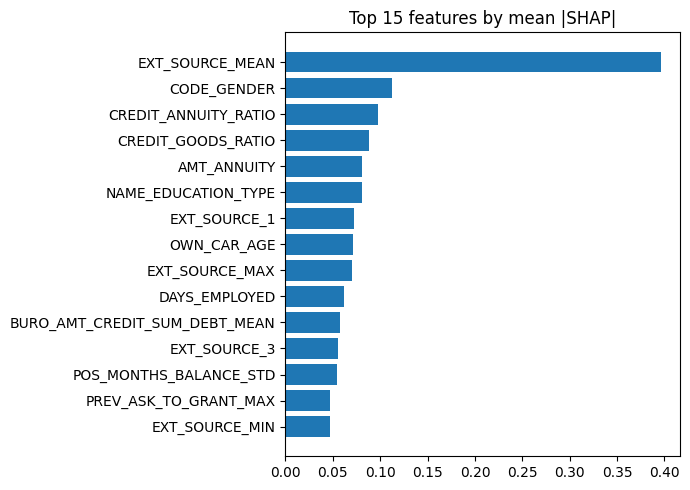

In [3]:
import matplotlib.pyplot as plt
top = imp.head(15).iloc[::-1]
plt.figure(figsize=(7,5))
plt.barh(top['feature'], top['mean_abs_shap'])
plt.title('Top 15 features by mean |SHAP|'); plt.tight_layout()

The engineered ratios (`CREDIT_ANNUITY_RATIO`, `CREDIT_GOODS_RATIO`, `EXT_SOURCE_MEAN`) and relational aggregates (`BURO_*`, `POS_*`, `PREV_*`) rank highly, which shows the feature engineering was worthwhile.

## Saved SHAP plots

`main.py shap` also saves summary, bar and dependence plots under `reports/figures/`.

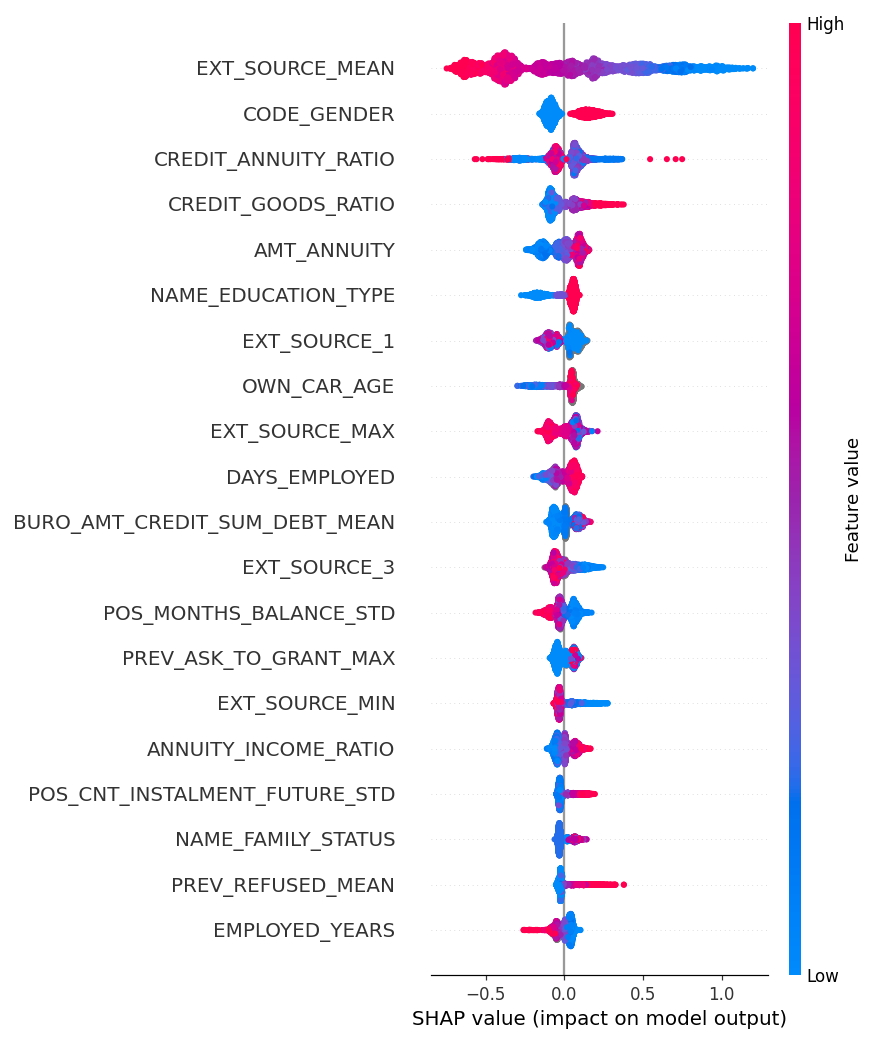

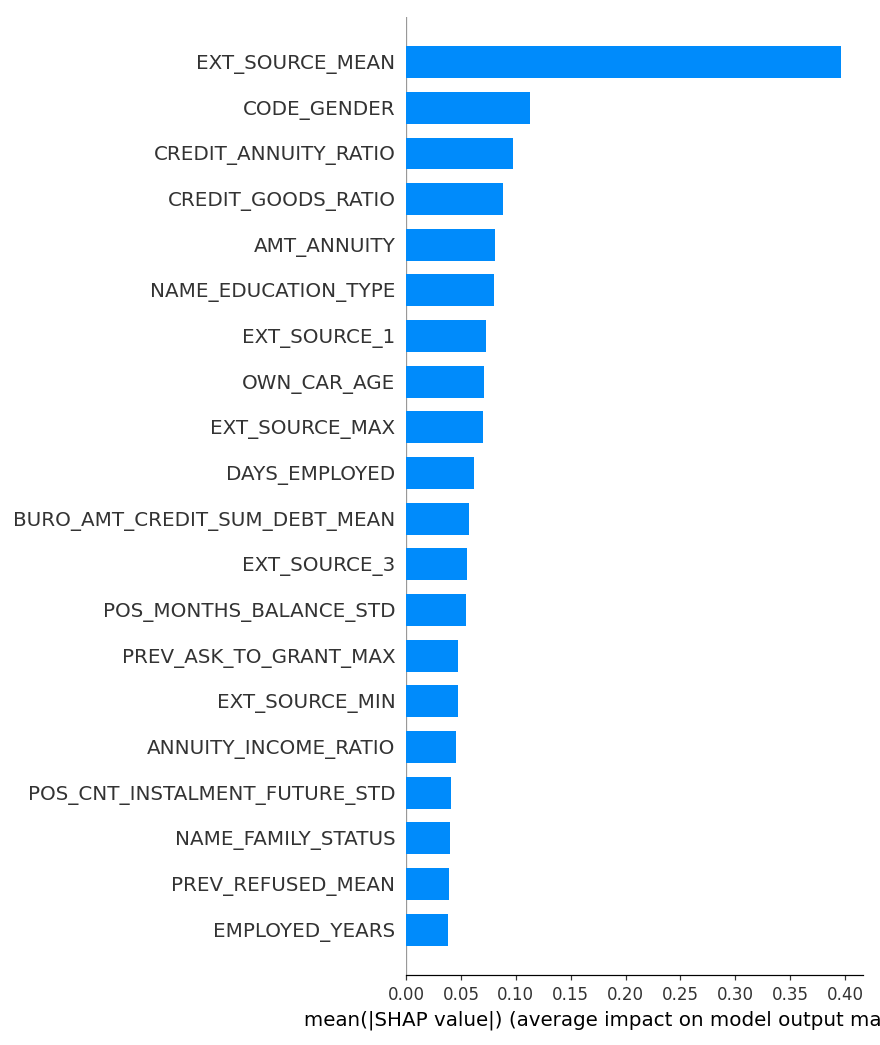

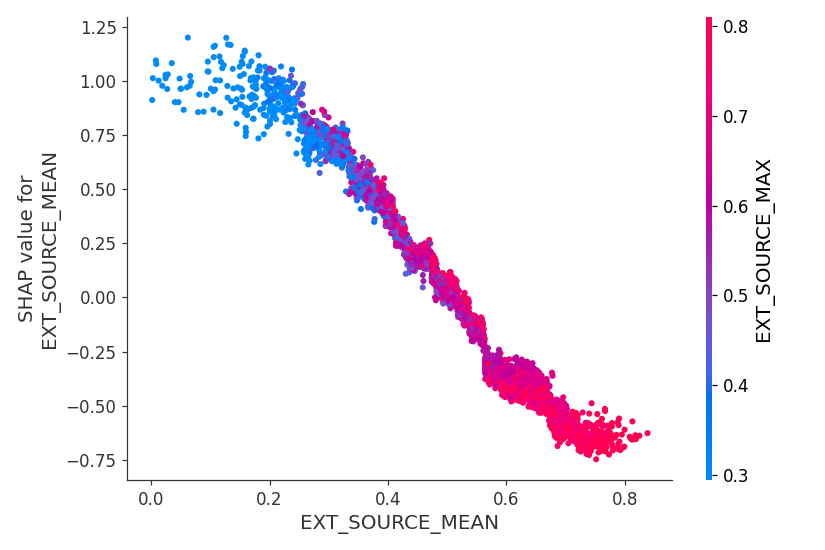

In [4]:
from IPython.display import Image, display
import os
for f in ['shap_summary.png','shap_bar.png','shap_dependence_EXT_SOURCE_MEAN.png']:
    p = os.path.join('reports/figures', f)
    if os.path.exists(p):
        display(Image(p))

## Per-applicant explanations

Top risk-increasing and risk-reducing features for a few example applicants, with the decision the bands imply.

In [5]:
examples = json.load(open('reports/tables/sample_predictions.json'))
for e in examples[:3]:
    print(f"applicant {e['applicant_id']}: PD={e['probability_of_default']} -> {e['decision']} ({e['risk_category']})")
    print('   increases risk:', e['top_risk_increasing'][:3])
    print('   reduces risk:  ', e['top_risk_reducing'][:3])
    print()

applicant 116731: PD=0.1001 -> APPROVE (LOW)
   increases risk: ['CODE_GENDER (+0.178)', 'CREDIT_GOODS_RATIO (+0.173)', 'BURO_AMT_CREDIT_SUM_DEBT_MEAN (+0.120)']
   reduces risk:   ['NAME_EDUCATION_TYPE (-0.129)', 'PREV_AMT_ANNUITY_MEAN (-0.107)', 'PREV_AMT_DOWN_PAYMENT_SUM (-0.050)']

applicant 209765: PD=0.0541 -> APPROVE (LOW)
   increases risk: ['ANNUITY_INCOME_RATIO (+0.096)', 'NAME_FAMILY_STATUS (+0.083)', 'EXT_SOURCE_MAX (+0.074)']
   reduces risk:   ['NAME_EDUCATION_TYPE (-0.193)', 'CREDIT_GOODS_RATIO (-0.130)', 'EXT_SOURCE_1 (-0.112)']

applicant 131190: PD=0.1344 -> APPROVE (LOW)
   increases risk: ['EXT_SOURCE_MEAN (+0.778)', 'CREDIT_GOODS_RATIO (+0.150)', 'CREDIT_ANNUITY_RATIO (+0.119)']
   reduces risk:   ['AMT_ANNUITY (-0.156)', 'CODE_GENDER (-0.096)', 'DAYS_ID_PUBLISH (-0.087)']



## Scoring a raw applicant

The `CreditRiskPredictor` ties it together: raw record in, probability + decision out.

In [6]:
from src.models.predict import CreditRiskPredictor
from src.data.load_data import load_config, raw_path
cfg = load_config()
predictor = CreditRiskPredictor()
raw = pd.read_csv(raw_path(cfg,'application_test'), nrows=3)
for _, row in raw.iterrows():
    print(predictor.predict(row.to_dict()))

{'probability_of_default': 0.0289, 'risk_category': 'LOW', 'decision': 'APPROVE'}
{'probability_of_default': 0.1034, 'risk_category': 'LOW', 'decision': 'APPROVE'}
{'probability_of_default': 0.0212, 'risk_category': 'LOW', 'decision': 'APPROVE'}
